# Linear and Polynomial Regression of the California Housing dataset

Let's start by importing the necessary libraries and print the description of the dataset.

In [235]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [236]:


housing = datasets.fetch_california_housing(return_X_y=True, as_frame=True)

print(datasets.fetch_california_housing().DESCR)

housing[0].head()

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [237]:
print(datasets.fetch_california_housing().target_names)
housing[1]

['MedHouseVal']


0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

#### For comfortability, let's add the target variable as a column to the dataframe.

Also I want to check if there are any missing values.

In [238]:

housing[0][datasets.fetch_california_housing().target_names[0]] = housing[1]
new_housing = pd.DataFrame(housing[0], columns=housing[0].columns)

print(new_housing.info())
new_housing.head()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


#### Now let's check the correlation between the features.

               MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc       1.000000 -0.119034  0.326895  -0.062040    0.004834  0.018766   
HouseAge    -0.119034  1.000000 -0.153277  -0.077747   -0.296244  0.013191   
AveRooms     0.326895 -0.153277  1.000000   0.847621   -0.072213 -0.004852   
AveBedrms   -0.062040 -0.077747  0.847621   1.000000   -0.066197 -0.006181   
Population   0.004834 -0.296244 -0.072213  -0.066197    1.000000  0.069863   
AveOccup     0.018766  0.013191 -0.004852  -0.006181    0.069863  1.000000   
Latitude    -0.079809  0.011173  0.106389   0.069721   -0.108785  0.002366   
Longitude   -0.015176 -0.108197 -0.027540   0.013344    0.099773  0.002476   
MedHouseVal  0.688075  0.105623  0.151948  -0.046701   -0.024650 -0.023737   

             Latitude  Longitude  MedHouseVal  
MedInc      -0.079809  -0.015176     0.688075  
HouseAge     0.011173  -0.108197     0.105623  
AveRooms     0.106389  -0.027540     0.151948  
AveBedrms    0.069721   0.0

Text(0.5, 1.0, 'Correlation Matrix of California Housing Dataset')

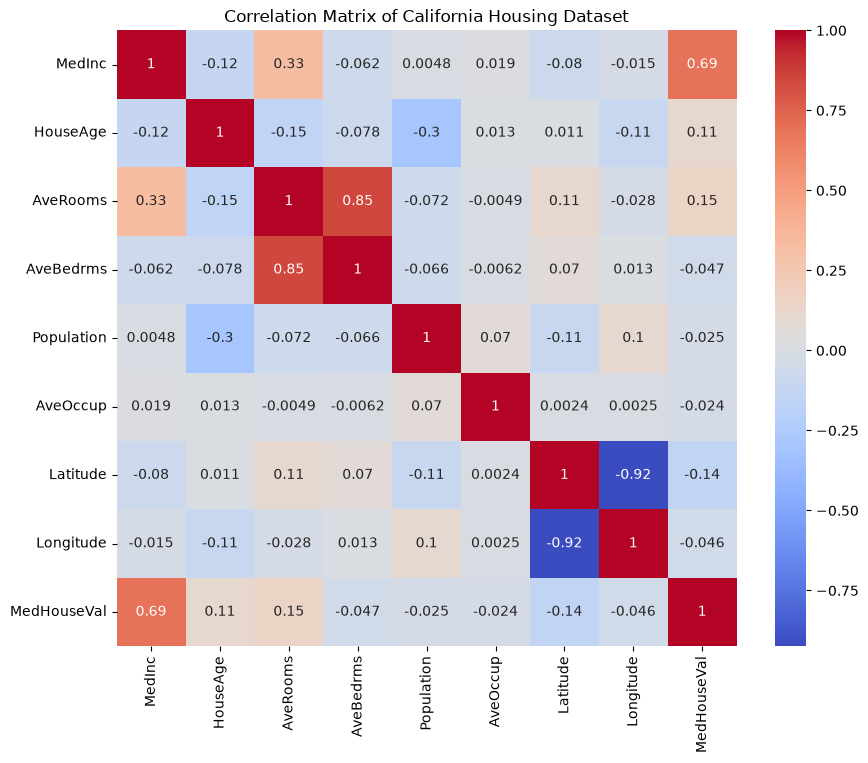

In [239]:
fig, ax = plt.subplots(figsize=(10, 8))
print(new_housing.corr())
sns.heatmap(new_housing.corr(), annot=True, cmap='coolwarm', ax=ax)
plt.title('Correlation Matrix of California Housing Dataset')

From the information above, we can see that there is a strong correlation between `MedInc` and `MedHouseVal` but not strong enough to be used as a complete feature

<Axes: xlabel='MedInc', ylabel='MedHouseVal'>

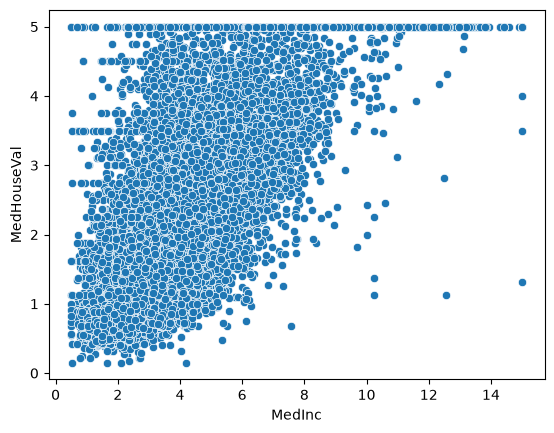

In [240]:
sns.scatterplot(x='MedInc', y='MedHouseVal', data=new_housing)

The plot looks like a linear relationship but there are some outliers for `MedHouseVal` = 5 and others. Maybe there is a way to filter them out.

In [241]:
print(new_housing['MedHouseVal'].describe())

# Ile obserwacji ma wartość przyciętą?
print((new_housing['MedHouseVal'] >= 5.0).sum())

# Zobaczmy czy przy wysokim MedInc nadal trafiamy do 5.0
new_housing[new_housing['MedHouseVal'] >= 5.0][['MedInc', 'MedHouseVal', 'Latitude', 'Longitude']].head(15)

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64
992


,MedInc,MedHouseVal,Latitude,Longitude
89,1.2434,5.00001,37.80,-122.27
459,1.1696,5.00001,37.87,-122.25
493,7.8521,5.00001,37.86,-122.24
494,9.3959,5.00001,37.85,-122.24
509,7.8772,5.00001,37.83,-122.23
510,11.8603,5.00001,37.82,-122.22
511,13.4990,5.00001,37.82,-122.22
512,12.2138,5.00001,37.82,-122.23
514,12.3804,5.00001,37.82,-122.23
517,8.7477,5.00001,37.82,-122.23


In this case, we can see accumualtion of 5.00001 values. It's unnatural for a median to have so many maximal values.

### Let's filter them out

<Axes: xlabel='MedInc', ylabel='MedHouseVal'>

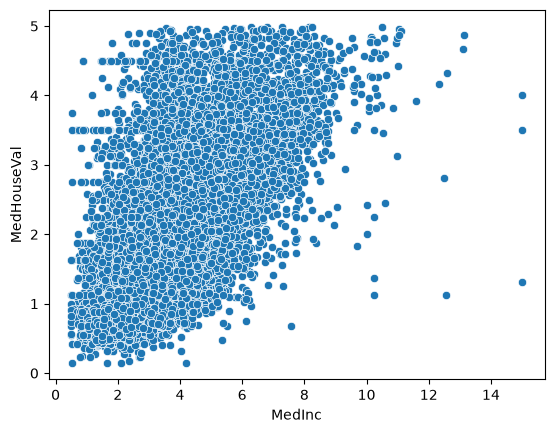

In [242]:
new_housing = new_housing[new_housing['MedHouseVal'] < 5]

sns.scatterplot(x='MedInc', y='MedHouseVal', data=new_housing)

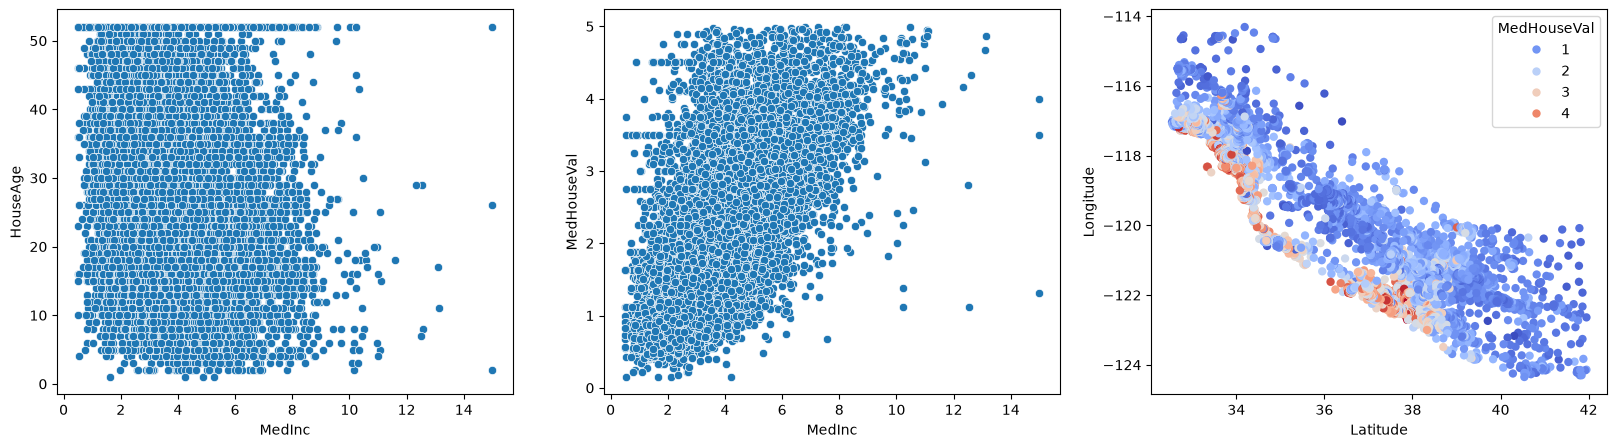

In [243]:
fig, ax = plt.subplots(1, 3,figsize=(20, 5))
ax[0] = sns.scatterplot(x='MedInc', y='HouseAge', data=new_housing, ax=ax[0])
ax[1] = sns.scatterplot(x='MedInc', y='MedHouseVal', data=new_housing, ax=ax[1])
ax[2] =sns.scatterplot(x='Latitude', y='Longitude', ax=ax[2], data=new_housing ,hue=new_housing['MedHouseVal'], palette='coolwarm', edgecolor='none')

#### Now let's test model performance on filtered dataset

In [244]:
X = new_housing['MedInc'].to_numpy().reshape(-1, 1)
y = new_housing['MedHouseVal'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print(X.shape, y.shape)
print(X_test.shape, y_test.shape)

(19648, 1) (19648,)
(3930, 1) (3930,)


RMSE: 0.754 (39.1%)
Model determination:  0.4125468888434378


<Axes: xlabel='Median income', ylabel='Median house value'>

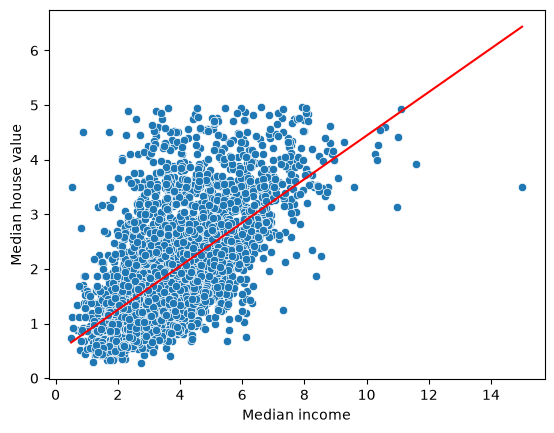

In [245]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

pred = lin_reg.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')

score = lin_reg.score(X_test, y_test)
print('Model determination: ', score)

sns.scatterplot(x=X_test[:,0], y=y_test)
plt.xlabel('Median income')
plt.ylabel('Median house value')
sns.lineplot(x=X_test[:,0], y=pred, color='red')

RMSE: 0.754 (39.1%)
Model determination:  0.41302103536132817


<Axes: xlabel='Median income', ylabel='Median house value'>

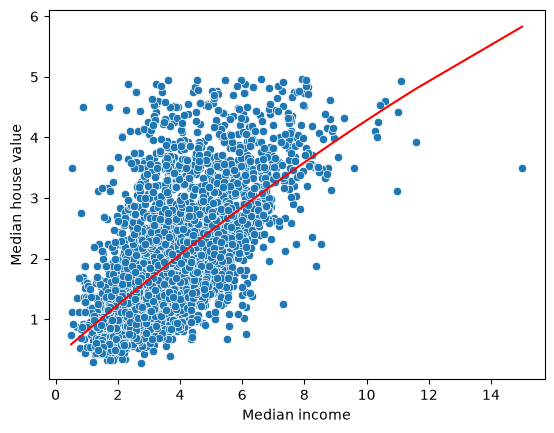

In [246]:
pipeline = make_pipeline(PolynomialFeatures(2), LinearRegression())

pipeline.fit(X_train,y_train)

pred = pipeline.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')

score = pipeline.score(X_test, y_test)
print('Model determination: ', score)

sns.scatterplot(x=X_test[:,0], y=y_test)
plt.xlabel('Median income')
plt.ylabel('Median house value')
sns.lineplot(x=X_test[:,0], y=pred, color='red')

#### It's not too bad but it can be better.

Let's add more features

<Axes: xlabel='Longitude', ylabel='Latitude'>

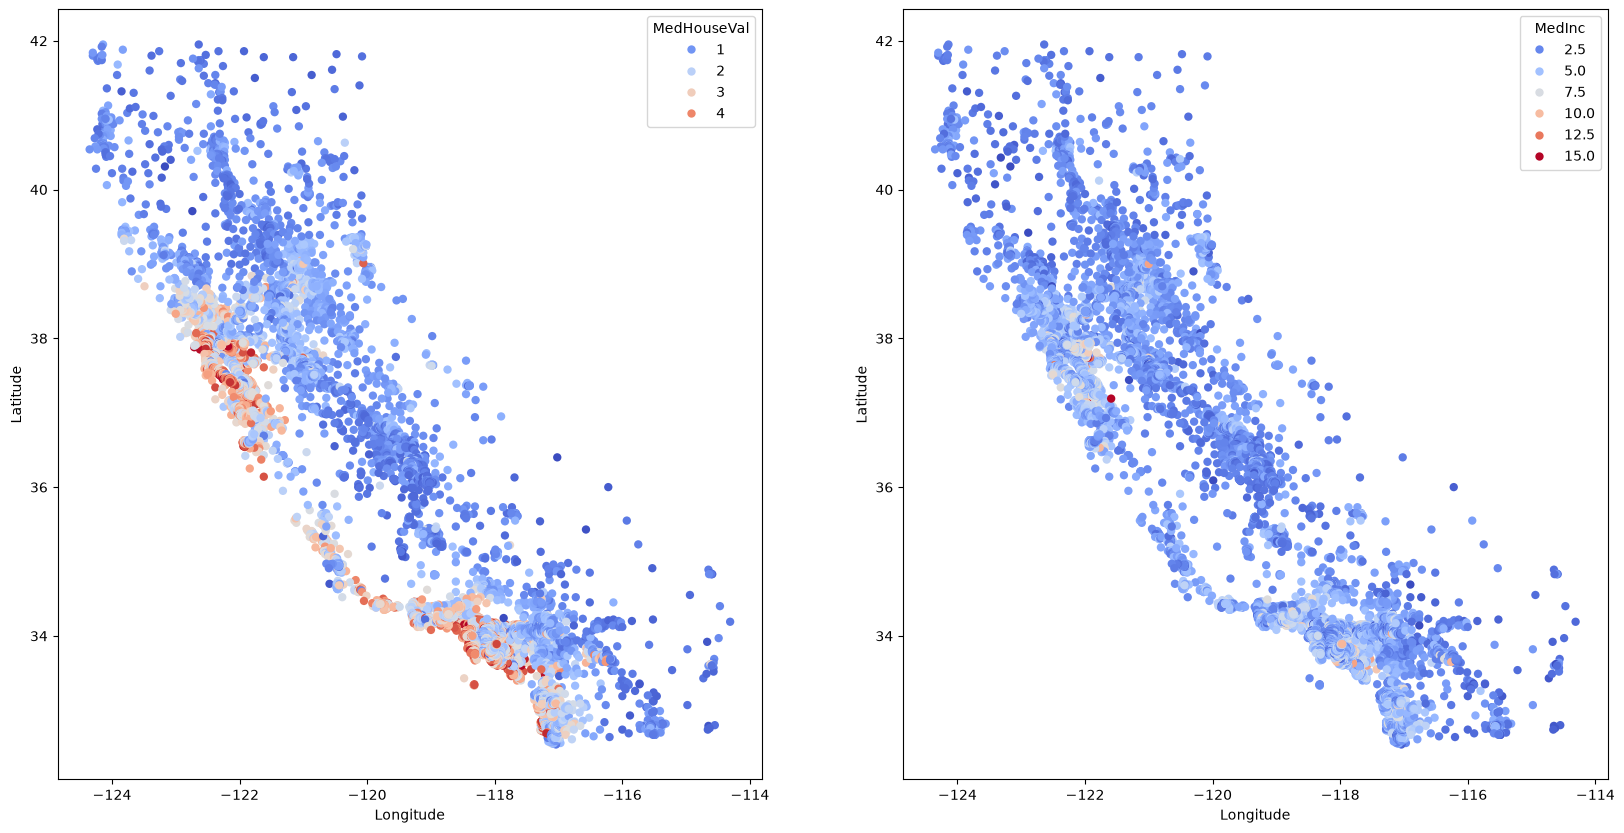

In [247]:
fig, ax = plt.subplots(1, 2,figsize=(20, 10))
sns.scatterplot(x="Longitude", y="Latitude", hue='MedHouseVal', data=new_housing, ax=ax[0], palette='coolwarm', edgecolor='none')
sns.scatterplot(x="Longitude", y="Latitude", hue='MedInc', data=new_housing, ax=ax[1], palette='coolwarm', edgecolor='none')

Looking at the plots, we can see that `Latitude` and `Longitude` are related to `MedHouseVal` and `MedInc` respectively.

With this knwoledge, we can add `Latitude`, `Longitude` along with `MedInc`

Also there are some features that are related to each other. I will try create new features from those

<Axes: xlabel='BedromsRoomsRatio', ylabel='MedHouseVal'>

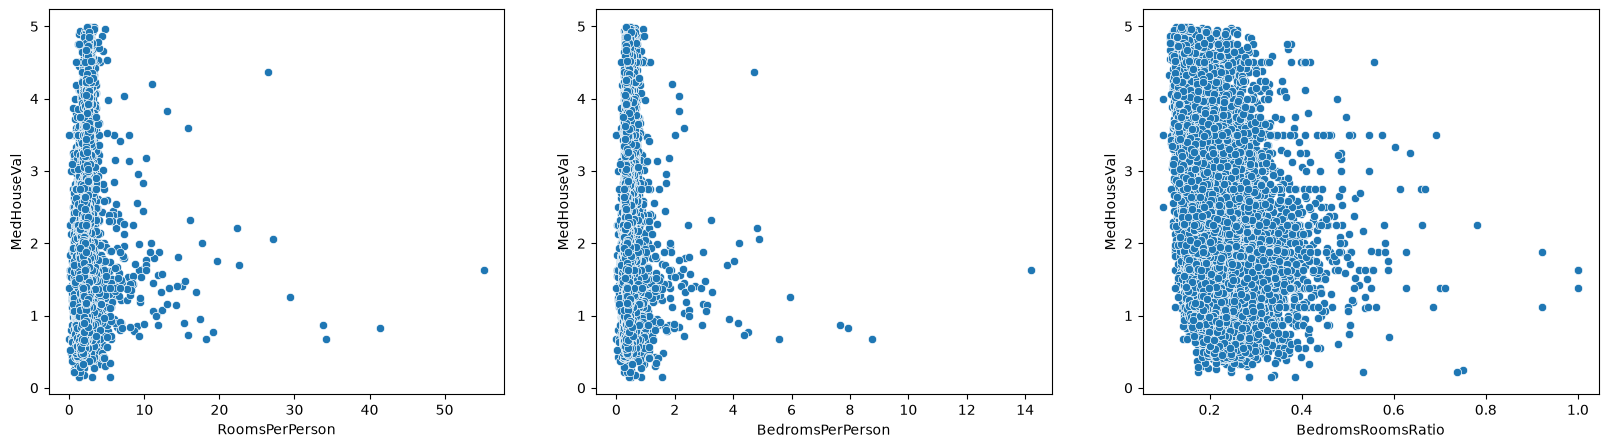

In [248]:
RoomsPerPerson = new_housing['AveRooms'] / new_housing['AveOccup']
BedromsPerPerson = new_housing['AveBedrms'] / new_housing['AveOccup']
BedromsRoomsRatio = new_housing['AveBedrms'] / new_housing['AveRooms']

new_housing['RoomsPerPerson'] = RoomsPerPerson
new_housing['BedromsPerPerson'] = BedromsPerPerson
new_housing['BedromsRoomsRatio'] = BedromsRoomsRatio


fig, ax = plt.subplots(1, 3,figsize=(20, 5))

sns.scatterplot(x="RoomsPerPerson", y="MedHouseVal", data=new_housing, ax=ax[0])
sns.scatterplot(x="BedromsPerPerson", y="MedHouseVal", data=new_housing, ax=ax[1])
sns.scatterplot(x="BedromsRoomsRatio", y="MedHouseVal", data=new_housing, ax=ax[2])



LinearRegression
RMSE: 0.636 (33.0%)
Model determination:  0.5820583336211783

PolynomialRegression
RMSE: 0.59 (30.7%)
Model determination:  0.6401805244763703


<Axes: xlabel='Median house value (actual)', ylabel='Median house value (predicted)'>

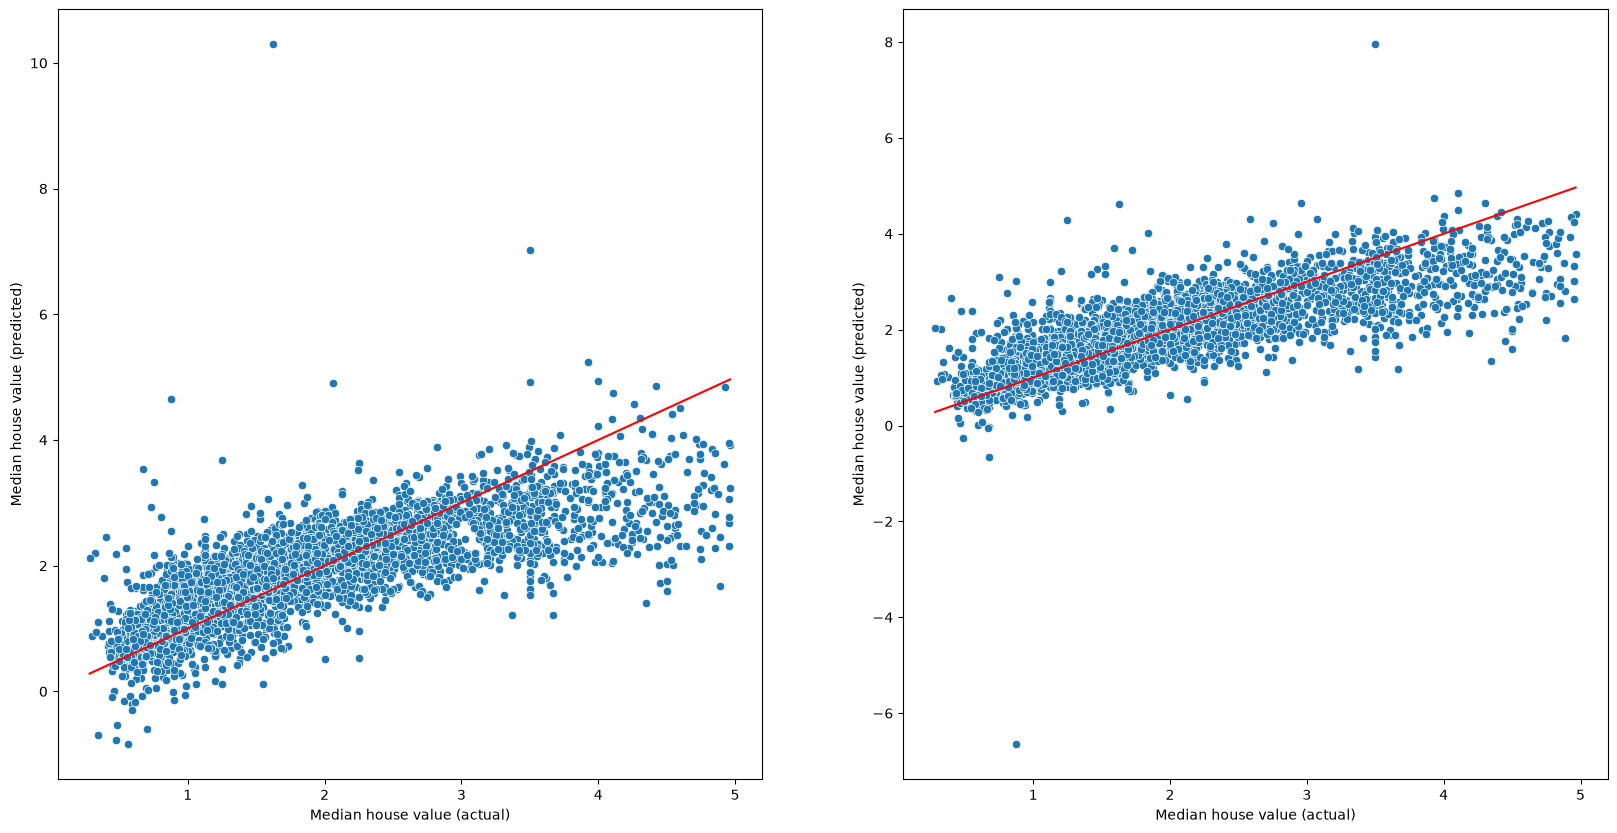

In [249]:
X = new_housing[['MedInc', 'HouseAge', 'Latitude', 'Longitude', 'RoomsPerPerson', 'BedromsPerPerson', 'BedromsRoomsRatio']].to_numpy()
y = new_housing['MedHouseVal'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

pred = lin_reg.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, pred))
print('LinearRegression')
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')

score = lin_reg.score(X_test, y_test)
print('Model determination: ', score)

fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(20, 10))

sns.scatterplot(x=y_test, y=pred , ax=ax1)
ax1.set_xlabel('Median house value (actual)')
ax1.set_ylabel('Median house value (predicted)')
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red' , ax=ax1)

pipeline = make_pipeline(PolynomialFeatures(2), LinearRegression())

pipeline.fit(X_train,y_train)

pred = pipeline.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, pred))
print('\nPolynomialRegression')
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')

score = pipeline.score(X_test, y_test)
print('Model determination: ', score)

sns.scatterplot(x=y_test, y=pred, ax=ax2)
ax2.set_xlabel('Median house value (actual)')
ax2.set_ylabel('Median house value (predicted)')
sns.lineplot(x=[y_test.min(), y_test.max()], y=[y_test.min(), y_test.max()], color='red', ax=ax2)

New features clearly improved the model. From `R2 = 0.41` to `R2 = 0.64`.

Also, we can see that the Polynomial Regression is better than Linear Regression for this dataset.